<a href="https://colab.research.google.com/github/Rhema5/CSA47-Deep-Learning/blob/main/DL_LAB_PROG_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Embedding, Dense

source = ["hello", "how are you", "good morning", "thank you"]
target = ["hola", "como estas", "buenos dias", "gracias"]

src_tokenizer = tf.keras.preprocessing.text.Tokenizer()
tgt_tokenizer = tf.keras.preprocessing.text.Tokenizer()

src_tokenizer.fit_on_texts(source)
tgt_tokenizer.fit_on_texts(target)

src = src_tokenizer.texts_to_sequences(source)
tgt = tgt_tokenizer.texts_to_sequences(target)

src = tf.keras.preprocessing.sequence.pad_sequences(src, padding="post")
tgt = tf.keras.preprocessing.sequence.pad_sequences(tgt, padding="post")

decoder_input = np.zeros_like(tgt)
decoder_input[:, 1:] = tgt[:, :-1]

src_vocab = len(src_tokenizer.word_index) + 1
tgt_vocab = len(tgt_tokenizer.word_index) + 1

encoder_input = Input(shape=(None,))
enc_emb = Embedding(src_vocab, 32)(encoder_input)
_, state_h, state_c = LSTM(64, return_state=True)(enc_emb)

decoder_input_layer = Input(shape=(None,))
dec_emb = Embedding(tgt_vocab, 32)(decoder_input_layer)
dec_out = LSTM(64, return_sequences=True)(dec_emb, initial_state=[state_h, state_c])
output = Dense(tgt_vocab, activation="softmax")(dec_out)

model = Model([encoder_input, decoder_input_layer], output)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

model.fit([src, decoder_input], tgt[..., None], epochs=100, verbose=0)

loss, accuracy = model.evaluate([src, decoder_input], tgt[..., None], verbose=0)
print("Translation Model Accuracy:", accuracy)
print("Translation Model Loss:", loss)

Translation Model Accuracy: 1.0
Translation Model Loss: 0.1318649798631668


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense

np.random.seed(42)

data = np.sin(np.arange(1000) * 0.05)

X = np.array([data[i:i+20] for i in range(len(data)-20)])
y = np.array([data[i+20] for i in range(len(data)-20)])

X = X.reshape(-1, 20, 1)

results = {}

for name, layer in [("RNN", SimpleRNN(32)), ("LSTM", LSTM(32))]:
    model = Sequential([layer, Dense(1)])
    model.compile(optimizer="adam", loss="mse")
    model.fit(X[:700], y[:700], epochs=10, batch_size=32, verbose=0)
    loss = model.evaluate(X[700:], y[700:], verbose=0)
    results[name] = loss

for name, loss in results.items():
    print(name, "Test MSE:", loss)

RNN Test MSE: 0.0006005301256664097
LSTM Test MSE: 0.0001951408776221797


In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

np.random.seed(42)

data = pd.DataFrame({
    "Age": np.random.randint(20, 80, 100),
    "Blood_Pressure": np.random.randint(90, 180, 100),
    "Sugar_Level": np.random.randint(70, 200, 100),
    "Cholesterol": np.random.randint(120, 280, 100),
    "Heart_Rate": np.random.randint(60, 120, 100)
})

scaled_data = StandardScaler().fit_transform(data)

pca = PCA(n_components=2)
reduced_data = pca.fit_transform(scaled_data)

print("Original Shape:", data.shape)
print("Reduced Shape:", reduced_data.shape)
print("Explained Variance:", pca.explained_variance_ratio_)
print("Transformed Features:\n", reduced_data[:5])

Original Shape: (100, 5)
Reduced Shape: (100, 2)
Explained Variance: [0.27108593 0.23217449]
Transformed Features:
 [[ 1.01318685 -0.82888753]
 [-1.32739161 -1.30081943]
 [ 0.03362289 -0.17476263]
 [ 0.01646753  0.82659664]
 [-0.36871903 -0.119055  ]]


In [ ]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Original Features:", iris.data.shape[1])
print("Reduced Features:", X_pca.shape[1])
print("Explained Variance:", pca.explained_variance_ratio_)
print("Classification Accuracy:", accuracy_score(y_test, predictions))

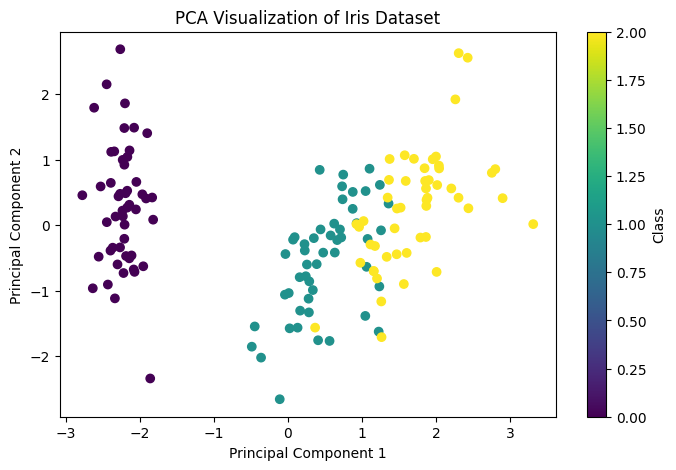

Explained Variance: [0.72962445 0.22850762]
Total Variance Retained: 0.9581320720000166


In [4]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=iris.target, cmap="viridis")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.colorbar(label="Class")
plt.show()

print("Explained Variance:", pca.explained_variance_ratio_)
print("Total Variance Retained:", sum(pca.explained_variance_ratio_))

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target

X = StandardScaler().fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model1 = RandomForestClassifier(random_state=42)
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)

pca = PCA(n_components=10)
X_pca = pca.fit_transform(X)

X_train_pca, X_test_pca, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

model2 = RandomForestClassifier(random_state=42)
model2.fit(X_train_pca, y_train)
pred2 = model2.predict(X_test_pca)

print("Accuracy Before PCA:", accuracy_score(y_test, pred1))
print("Accuracy After PCA:", accuracy_score(y_test, pred2))
print("Variance Retained:", sum(pca.explained_variance_ratio_))

Accuracy Before PCA: 0.9649122807017544
Accuracy After PCA: 0.956140350877193
Variance Retained: 0.951568814336667


In [6]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data = load_breast_cancer()
X = StandardScaler().fit_transform(data.data)

pca = PCA()
pca.fit(X)

variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

components = np.argmax(cumulative_variance >= 0.95) + 1

print("Explained Variance:\n", variance)
print("Cumulative Explained Variance:\n", cumulative_variance)
print("Components Required for 95% Variance:", components)

pca_95 = PCA(n_components=0.95)
reduced_data = pca_95.fit_transform(X)

print("Original Shape:", X.shape)
print("Reduced Shape:", reduced_data.shape)

Explained Variance:
 [4.42720256e-01 1.89711820e-01 9.39316326e-02 6.60213492e-02
 5.49576849e-02 4.02452204e-02 2.25073371e-02 1.58872380e-02
 1.38964937e-02 1.16897819e-02 9.79718988e-03 8.70537901e-03
 8.04524987e-03 5.23365745e-03 3.13783217e-03 2.66209337e-03
 1.97996793e-03 1.75395945e-03 1.64925306e-03 1.03864675e-03
 9.99096464e-04 9.14646751e-04 8.11361259e-04 6.01833567e-04
 5.16042379e-04 2.72587995e-04 2.30015463e-04 5.29779290e-05
 2.49601032e-05 4.43482743e-06]
Cumulative Explained Variance:
 [0.44272026 0.63243208 0.72636371 0.79238506 0.84734274 0.88758796
 0.9100953  0.92598254 0.93987903 0.95156881 0.961366   0.97007138
 0.97811663 0.98335029 0.98648812 0.98915022 0.99113018 0.99288414
 0.9945334  0.99557204 0.99657114 0.99748579 0.99829715 0.99889898
 0.99941502 0.99968761 0.99991763 0.99997061 0.99999557 1.        ]
Components Required for 95% Variance: 10
Original Shape: (569, 30)
Reduced Shape: (569, 10)


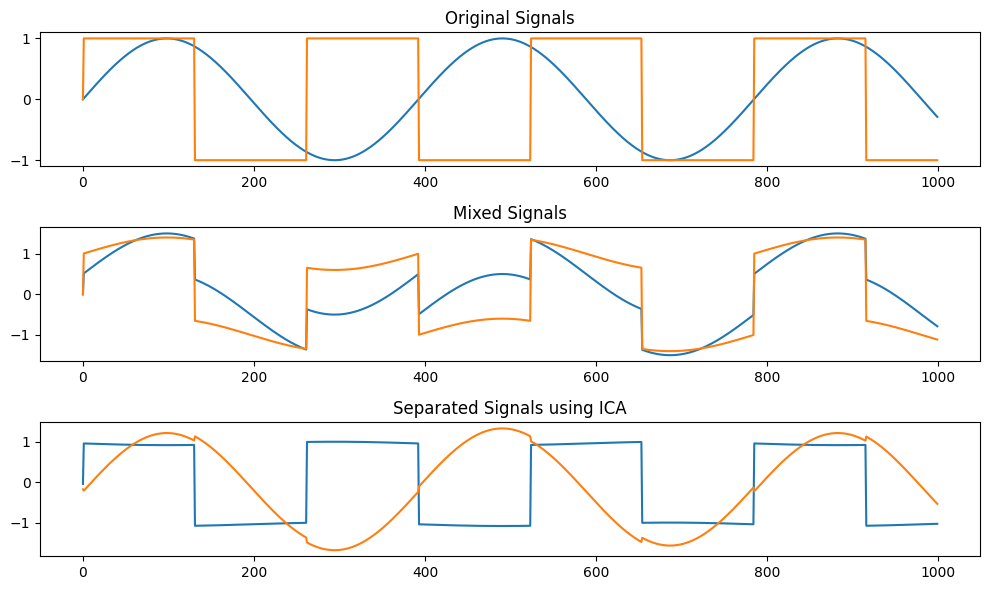

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

np.random.seed(42)

t = np.linspace(0, 8, 1000)

signal1 = np.sin(2 * t)
signal2 = np.sign(np.sin(3 * t))

sources = np.c_[signal1, signal2]

mixing_matrix = np.array([[1, 0.5], [0.4, 1]])
mixed_signals = sources @ mixing_matrix.T

ica = FastICA(n_components=2, random_state=42)
separated_signals = ica.fit_transform(mixed_signals)

plt.figure(figsize=(10, 6))

plt.subplot(3, 1, 1)
plt.plot(sources)
plt.title("Original Signals")

plt.subplot(3, 1, 2)
plt.plot(mixed_signals)
plt.title("Mixed Signals")

plt.subplot(3, 1, 3)
plt.plot(separated_signals)
plt.title("Separated Signals using ICA")

plt.tight_layout()
plt.show()

Mixed Signal Shape: (1000, 2)
Separated Signal Shape: (1000, 2)
Reconstruction Error: 9.74905188481534e-32


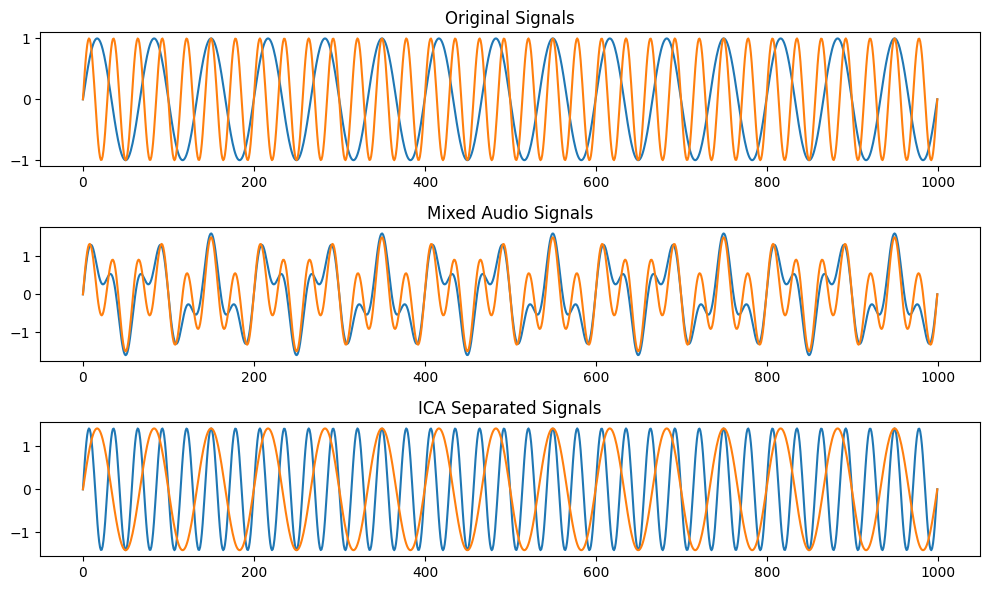

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA
from sklearn.metrics import mean_squared_error

np.random.seed(42)

t = np.linspace(0, 5, 1000)

voice1 = np.sin(2 * np.pi * 3 * t)
voice2 = np.sin(2 * np.pi * 7 * t)

original = np.c_[voice1, voice2]

mixing_matrix = np.array([[1, 0.6], [0.5, 1]])
mixed = original @ mixing_matrix.T

ica = FastICA(n_components=2, random_state=42, max_iter=1000)
separated = ica.fit_transform(mixed)

print("Mixed Signal Shape:", mixed.shape)
print("Separated Signal Shape:", separated.shape)
print("Reconstruction Error:", mean_squared_error(mixed, ica.inverse_transform(separated)))

plt.figure(figsize=(10, 6))

plt.subplot(3, 1, 1)
plt.plot(original)
plt.title("Original Signals")

plt.subplot(3, 1, 2)
plt.plot(mixed)
plt.title("Mixed Audio Signals")

plt.subplot(3, 1, 3)
plt.plot(separated)
plt.title("ICA Separated Signals")

plt.tight_layout()
plt.show()

In [9]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FastICA

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
pca_features = pca.fit_transform(X)

ica = FastICA(n_components=2, random_state=42, max_iter=1000)
ica_features = ica.fit_transform(X)

print("PCA Features:\n", pca_features[:5])
print("ICA Features:\n", ica_features[:5])

print("PCA Explained Variance:", pca.explained_variance_ratio_)
print("PCA Total Variance:", sum(pca.explained_variance_ratio_))

print("ICA Components:\n", ica.components_)
print("ICA Reconstruction Error:", np.mean((X - ica.inverse_transform(ica_features)) ** 2))

PCA Features:
 [[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]
ICA Features:
 [[-1.31297046  0.53439339]
 [-1.23499905 -0.67509574]
 [-1.39225584 -0.32364276]
 [-1.36085126 -0.59172328]
 [-1.38192872  0.71061133]]
PCA Explained Variance: [0.72962445 0.22850762]
PCA Total Variance: 0.9581320720000166
ICA Components:
 [[ 0.3145811  -0.13397726  0.34027375  0.33225723]
 [ 0.38718349  0.96931051  0.01729336  0.06190482]]
ICA Reconstruction Error: 0.0418679279999836


In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

np.random.seed(42)

data = pd.DataFrame({
    "Marks": np.random.randint(40, 100, 100),
    "Attendance": np.random.randint(50, 100, 100),
    "Assignment": np.random.randint(40, 100, 100),
    "Participation": np.random.randint(30, 100, 100),
    "Study_Hours": np.random.randint(1, 10, 100)
})

X = StandardScaler().fit_transform(data)

fa = FactorAnalysis(n_components=2, random_state=42)
factors = fa.fit_transform(X)

print("Original Data:\n", data.head())
print("Extracted Factors:\n", factors[:5])
print("Factor Loadings:\n", fa.components_)

Original Data:
    Marks  Attendance  Assignment  Participation  Study_Hours
0     78          63          97             81            1
1     91          72          94             62            8
2     68          89          67             69            1
3     54          70          64             68            9
4     82          65          78             30            6
Extracted Factors:
 [[ 1.21869482  0.24852169]
 [-0.21134225  1.38174487]
 [ 0.93947326 -0.70397654]
 [-1.34435979  0.16700286]
 [-0.01869201  0.67804398]]
Factor Loadings:
 [[ 0.53913051  0.12862207  0.18961254 -0.00491221 -0.69028708]
 [ 0.31682584 -0.06361027  0.5872205  -0.12327698  0.29161642]]


In [11]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

np.random.seed(42)

data = pd.DataFrame({
    "Electronics": np.random.randint(1, 10, 100),
    "Clothing": np.random.randint(1, 10, 100),
    "Groceries": np.random.randint(1, 10, 100),
    "Online_Orders": np.random.randint(1, 15, 100),
    "Discount_Usage": np.random.randint(1, 10, 100),
    "Monthly_Spending": np.random.randint(500, 10000, 100)
})

X = StandardScaler().fit_transform(data)

fa = FactorAnalysis(n_components=2, random_state=42)
customer_factors = fa.fit_transform(X)

print("Customer Data:\n", data.head())
print("Latent Customer Factors:\n", customer_factors[:5])
print("Factor Loadings:\n", fa.components_)

Customer Data:
    Electronics  Clothing  Groceries  Online_Orders  Discount_Usage  \
0            7         3          1             10               5   
1            4         5          9              1               1   
2            8         3          9              8               7   
3            5         1          2              1               5   
4            7         5          7              9               6   

   Monthly_Spending  
0              5986  
1              8835  
2              5480  
3              7766  
4              4991  
Latent Customer Factors:
 [[ 0.63884797  0.5536566 ]
 [-1.02272517 -0.23724374]
 [-0.37199558 -1.11677228]
 [-0.1004815   1.04435486]
 [-0.06886079 -0.7605216 ]]
Factor Loadings:
 [[ 0.49976627  0.14272021 -0.43071642  0.05335346 -0.24368288 -0.47616284]
 [-0.32680279 -0.23021114 -0.5137067  -0.1984847  -0.11784186  0.19716893]]


In [12]:
  import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.metrics import mean_squared_error

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
pca_features = pca.fit_transform(X)
pca_reconstructed = pca.inverse_transform(pca_features)

fa = FactorAnalysis(n_components=2, random_state=42)
fa_features = fa.fit_transform(X)
fa_reconstructed = fa_features @ fa.components_ + fa.mean_

pca_error = mean_squared_error(X, pca_reconstructed)
fa_error = mean_squared_error(X, fa_reconstructed)

print("Original Shape:", X.shape)
print("PCA Reduced Shape:", pca_features.shape)
print("Factor Analysis Shape:", fa_features.shape)

print("PCA Reconstruction Error:", pca_error)
print("Factor Analysis Reconstruction Error:", fa_error)

Original Shape: (150, 4)
PCA Reduced Shape: (150, 2)
Factor Analysis Shape: (150, 2)
PCA Reconstruction Error: 0.04186792799998359
Factor Analysis Reconstruction Error: 0.14044617593776276


Generated Data:
 [[ 5.29594281 10.88980204]
 [ 7.24461942 10.13005954]
 [ 4.53386694  9.76157387]
 [ 7.2580435  12.09893911]
 [ 5.16974361  8.90988419]]
Actual Mean: [5, 10]
Estimated Mean:
 [ 5.09203385 10.01939811]
Actual Covariance:
 [[2, 0.8], [0.8, 3]]
Estimated Covariance:
 [[1.97989687 0.67323524]
 [0.67323524 2.80766946]]


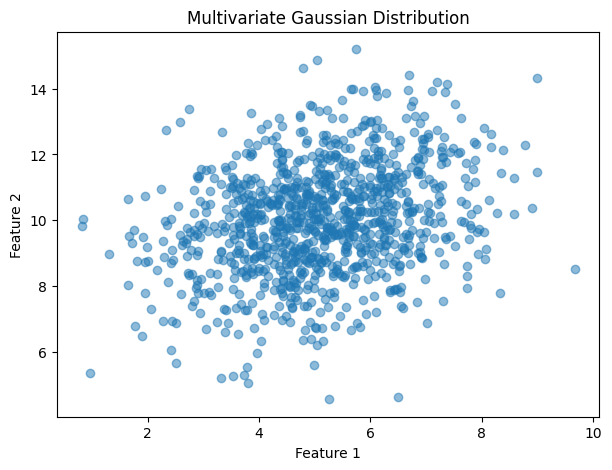

In [13]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

mean = [5, 10]
covariance = [[2, 0.8], [0.8, 3]]

data = np.random.multivariate_normal(mean, covariance, 1000)

estimated_mean = np.mean(data, axis=0)
estimated_covariance = np.cov(data, rowvar=False)

print("Generated Data:\n", data[:5])
print("Actual Mean:", mean)
print("Estimated Mean:\n", estimated_mean)
print("Actual Covariance:\n", covariance)
print("Estimated Covariance:\n", estimated_covariance)

plt.figure(figsize=(7, 5))
plt.scatter(data[:, 0], data[:, 1], alpha=0.5)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Multivariate Gaussian Distribution")
plt.show()

Customer Cluster Labels:
 [2 2 2 2 2 2 2 2 2 2]
Cluster Probabilities:
 [[1.73079094e-14 1.41187110e-21 1.00000000e+00]
 [2.63189112e-10 2.56892576e-18 1.00000000e+00]
 [1.34341734e-15 5.39751875e-23 1.00000000e+00]
 [1.01091410e-10 7.04346949e-18 1.00000000e+00]
 [4.80210457e-14 3.97116968e-22 1.00000000e+00]
 [2.39352731e-16 1.08995236e-23 1.00000000e+00]
 [2.03202567e-18 3.87813238e-24 1.00000000e+00]
 [1.60764771e-17 1.53788277e-25 1.00000000e+00]
 [4.65402819e-15 2.57519746e-23 1.00000000e+00]
 [9.81329284e-19 1.69224703e-25 1.00000000e+00]]
Cluster Means:
 [[ 0.16007443  0.00844258]
 [ 1.03461766  1.18574471]
 [-1.20428735 -1.20710433]]
Model AIC: 760.6889514167675
Model BIC: 823.653253485923


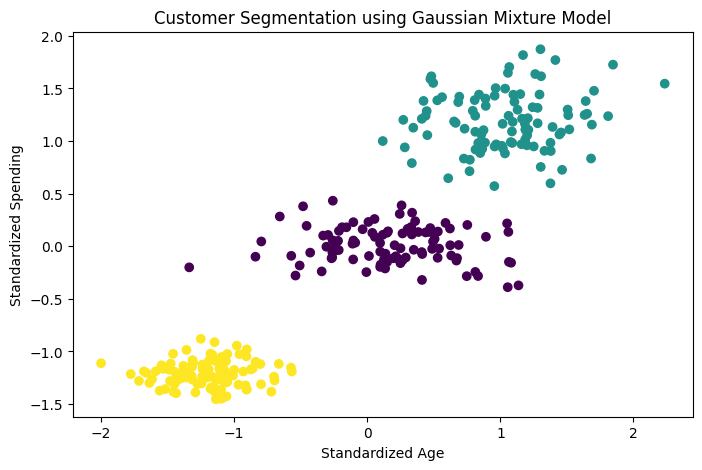

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

group1 = np.random.normal(loc=[25, 2000], scale=[5, 300], size=(100, 2))
group2 = np.random.normal(loc=[45, 5000], scale=[7, 500], size=(100, 2))
group3 = np.random.normal(loc=[60, 8000], scale=[6, 700], size=(100, 2))

data = np.vstack([group1, group2, group3])

X = StandardScaler().fit_transform(data)

gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)

labels = gmm.predict(X)
probabilities = gmm.predict_proba(X)

print("Customer Cluster Labels:\n", labels[:10])
print("Cluster Probabilities:\n", probabilities[:10])
print("Cluster Means:\n", gmm.means_)
print("Model AIC:", gmm.aic(X))
print("Model BIC:", gmm.bic(X))

plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.xlabel("Standardized Age")
plt.ylabel("Standardized Spending")
plt.title("Customer Segmentation using Gaussian Mixture Model")
plt.show()

In [15]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = load_breast_cancer()

X = data.data
y = data.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(X_train, y_train, epochs=30, batch_size=16, validation_split=0.2, verbose=1)

predictions = (model.predict(X_test) > 0.5).astype(int).ravel()

print("Test Accuracy:", accuracy_score(y_test, predictions))
print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))
print("Classification Report:\n", classification_report(y_test, predictions))

sample = X_test[:1]
prediction = model.predict(sample)

print("Predicted Class:", "Benign" if prediction[0][0] >= 0.5 else "Malignant")

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8324 - loss: 0.4356 - val_accuracy: 0.9451 - val_loss: 0.2569
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9451 - loss: 0.2227 - val_accuracy: 0.9560 - val_loss: 0.1418
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9505 - loss: 0.1525 - val_accuracy: 0.9670 - val_loss: 0.1016
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9615 - loss: 0.1182 - val_accuracy: 0.9890 - val_loss: 0.0809
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9725 - loss: 0.0963 - val_accuracy: 0.9890 - val_loss: 0.0706
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9808 - loss: 0.0766 - val_accuracy: 0.9890 - val_loss: 0.0649
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9780 - loss: 0.0737 - val_accuracy: 0.9890 - val_loss: 0.0582
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9808 - loss: 0.0701 - val_accuracy: 0.9890 - v